# IND320 - Project work, part 3: weather, outliers and time-series decomposition

- **Student:** Iftikhar Amiri
- **GitHub repository:** https://github.com/iftikharamiri/ind320 (part 3 was developed on the branch `part3` and merged into `main`)
- **Streamlit app:** https://ind320-iftikhar-amiri.streamlit.app/
- **Screencast:** https://github.com/iftikharamiri/ind320/raw/main/screencast/part3_screencast.mp4
  (the link downloads the video. On the GitHub file page, click **View raw** if the file is too big to preview.)

## Contents
1. Setup
2. Areas from NVE: electricity areas and precipitation areas
3. Random sample of 1000 locations per area
4. open-meteo: ERA5 download function, applied to NO3 in 2024
5. Outliers in precipitation: DCT high-pass and Statistical Process Control
6. Anomalies in temperature: Local Outlier Factor
7. STL decomposition of the reservoir fill level
8. Spectrogram of the reservoir fill level
9. AI usage
10. Log

## 1. Setup
Same environment and kernel as part 2 (**IND320 Spark (Python 3.11)**); Spark is not
used in this part. The analysis and download functions in this notebook are the same
code as in the app's `modules/analysis.py` and `modules/weather.py`, so the notebook
and the app always agree.

In [1]:
from pathlib import Path
from urllib.parse import quote_plus

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from pymongo import MongoClient

# Same colour-blind-checked palette and plot style as in parts 1 and 2
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
           "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 3.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})

# Passwords live outside the repository (see part 2)
SECRETS = Path("../../course-material/No_sync")
mongo_user, mongo_password = (SECRETS / "MongoDB").read_text().split("\n")[:2]
mongo = MongoClient(
    f"mongodb+srv://{quote_plus(mongo_user.strip())}:{quote_plus(mongo_password.strip())}"
    "@ind320.w1oh2ln.mongodb.net/",
    serverSelectionTimeoutMS=20000,
)
db = mongo["ind320"]
print("MongoDB ping:", mongo.admin.command("ping"))

MongoDB ping: {'ok': 1}


## 2. Areas from NVE
The Magasinstatistikk data from part 2 uses three kinds of areas: Norway as a whole
(`NO`), the electricity price areas NO1-NO5 (`EL`) and the watercourse/precipitation
areas (`VASS`). To download weather for an area, I need its outline.

**Electricity areas.** NVE's map portal atlas.nve.no shows them as the layer
*Budområde* (bidding area). The portal is built on NVE's map service
`kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0`, which can return the
same polygons as GeoJSON. I download them from there instead of clicking through the
portal: it is the same data, but reproducible from the notebook. I ask for GeoJSON
instead of a shapefile: the polygons are identical, but GeoJSON is a single text file
that Python reads without GIS packages, while a shapefile is several binary files
(.shp, .shx, .dbf, .prj). The query asks for
longitude/latitude (`outSR=4326`) and simplifies the coastline slightly
(`maxAllowableOffset`, about 500 m), which keeps the file small (~25 kB). The file is
stored in the repository, `data/areas/`.

In [2]:
AREAS_DIR = Path("../data/areas")
AREAS_DIR.mkdir(parents=True, exist_ok=True)

response = requests.get(
    "https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0/query",
    params={
        "where": "1=1",                # all features
        "outFields": "budomr",         # the area name, "NO 1" ... "NO 5"
        "outSR": 4326,                 # WGS84 longitude/latitude, what open-meteo wants
        "f": "geojson",
        "maxAllowableOffset": 0.005,   # simplify the coastline (degrees, ~500 m)
        "geometryPrecision": 4,
    },
    timeout=120,
)
response.raise_for_status()
(AREAS_DIR / "price_areas.geojson").write_text(response.text, encoding="utf-8")
print([f["properties"]["budomr"] for f in response.json()["features"]])

['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']


**Precipitation areas.** The Magasinstatistikk API has three watercourse areas
(`VASS` 1-3; its area list `HentOmråder` describes them as South-East, West and Mid/North
Norway). On atlas.nve.no they correspond to NVE's five regions, layer *NVE Region*
(service `Mapservices/Administrasjon2/MapServer/0`, field `REGION`). As noted in the
assignment, two of the watercourse areas are split over two regions, so the regions are
merged:

| Magasinstatistikk | App name | NVE regions |
|---|---|---|
| VASS 1 (East) | Watercourse 1 | RS (Sør) + RØ (Øst) |
| VASS 2 (West) | Watercourse 2 | RV (Vest) |
| VASS 3 (North) | Watercourse 3 | RM (Midt-Norge) + RN (Nord) |

The download works the same way as for the price areas, and the file is stored next to it.

NVE regions: ['RM', 'RN', 'RS', 'RV', 'RØ']


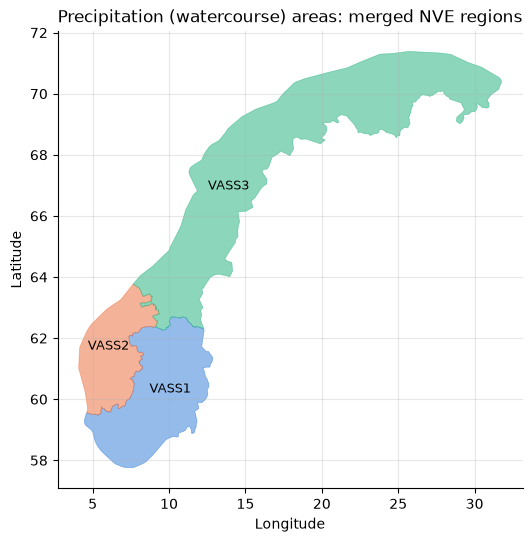

In [3]:
response = requests.get(
    "https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/0/query",
    params={"where": "1=1", "outFields": "REGION,REGIONNAVN", "outSR": 4326, "f": "geojson",
            "maxAllowableOffset": 0.005, "geometryPrecision": 4},
    timeout=120,
)
response.raise_for_status()
(AREAS_DIR / "nve_regions.geojson").write_text(response.text, encoding="utf-8")

# NVE region code -> Magasinstatistikk watercourse area (East = RS+RØ, North = RM+RN)
REGION_TO_VASS = {"RS": "VASS1", "RØ": "VASS1", "RV": "VASS2", "RM": "VASS3", "RN": "VASS3"}

from shapely.geometry import shape
from shapely.ops import unary_union

regions = {f["properties"]["REGION"]: shape(f["geometry"]).buffer(0) for f in response.json()["features"]}
print("NVE regions:", sorted(regions))
PRECIPITATION_AREAS = {
    vass: unary_union([poly for code, poly in regions.items() if REGION_TO_VASS[code] == vass])
    for vass in sorted(set(REGION_TO_VASS.values()))
}

fig, ax = plt.subplots(figsize=(6, 7))
for i, (name, poly) in enumerate(PRECIPITATION_AREAS.items()):
    for part in getattr(poly, "geoms", [poly]):
        ax.fill(*part.exterior.xy, alpha=0.5, color=PALETTE[i], linewidth=0.5)
    ax.annotate(name, poly.representative_point().coords[0], ha="center", fontsize=9)
ax.set_title("Precipitation (watercourse) areas: merged NVE regions")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(2)
plt.show()

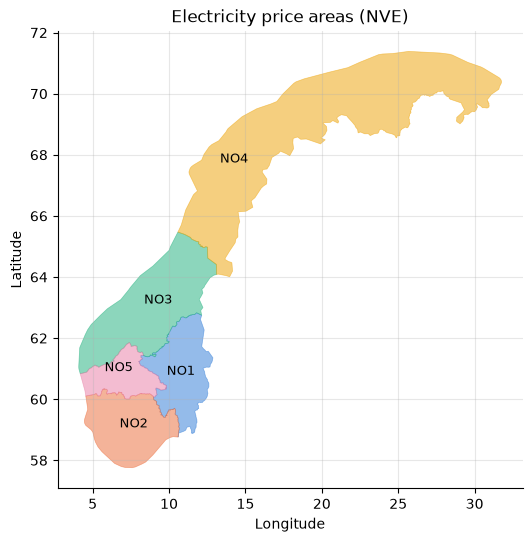

In [4]:
from shapely.geometry import shape
from shapely.ops import unary_union

def read_areas(path, name_field, rename=lambda s: s):
    # GeoJSON -> {area name: shapely polygon}
    import json
    features = json.loads(Path(path).read_text(encoding="utf-8"))["features"]
    return {rename(f["properties"][name_field]): shape(f["geometry"]) for f in features}

# Area names as in the app: NO1..NO5, Norway (the union of the price areas), VASS...
AREAS = read_areas(AREAS_DIR / "price_areas.geojson", "budomr", lambda s: s.replace(" ", ""))
AREAS["Norway"] = unary_union(list(AREAS.values()))
AREAS.update(PRECIPITATION_AREAS)

fig, ax = plt.subplots(figsize=(6, 7))
for i, name in enumerate(n for n in AREAS if n.startswith("NO") and n != "Norway"):
    poly = AREAS[name]
    for part in getattr(poly, "geoms", [poly]):
        ax.fill(*part.exterior.xy, alpha=0.5, color=PALETTE[i], linewidth=0.5)
    ax.annotate(name, poly.representative_point().coords[0], ha="center", fontsize=9)
ax.set_title("Electricity price areas (NVE)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(2)   # ~1/cos(60 deg): makes the map look less stretched at these latitudes
plt.show()

**Land only.** NVE's area polygons include the coastal sea: see the smooth arcs
outside the coast on the map. A first test with open-meteo's Elevation API showed that
28% of random points in NO2 and 40% in NO4 were in the sea, which would mix sea weather
into the area averages. (Checking every point with that API is not an option: each
coordinate counts against the free daily quota.) Instead I use NVE's catchment map
REGINE: the layer *Hovedfelt nedbørfelt til hav* has the 2053 catchments that drain to
the sea, including the small coastal strips between rivers. Catchments are land by
definition, so their union is a land outline of Norway with the fjords cut out. Each
area is clipped to it before sampling.

2053 catchments merged into one land outline


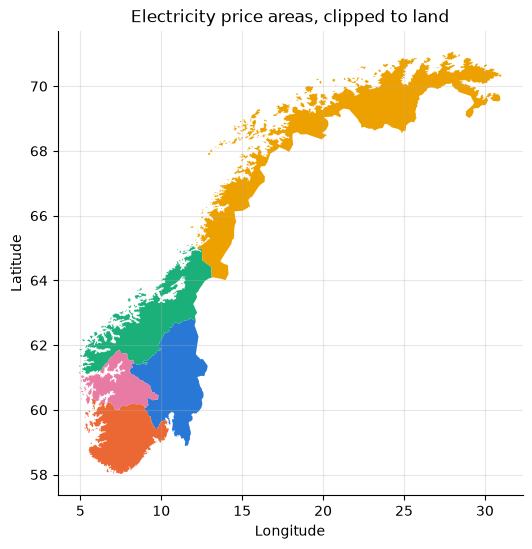

In [5]:
from shapely.geometry import mapping
import json

# The catchments come in two pages (the service returns at most 2000 features at a time)
catchments = []
for offset in (0, 2000):
    page = requests.get(
        "https://kart.nve.no/enterprise/rest/services/Nedborfelt2/MapServer/3/query",
        params={"where": "1=1", "outFields": "vassdragsnr", "outSR": 4326, "f": "geojson",
                "maxAllowableOffset": 0.003, "geometryPrecision": 4,
                "resultOffset": offset, "resultRecordCount": 2000, "orderByFields": "objectid"},
        timeout=300,
    ).json()
    catchments += [shape(f["geometry"]).buffer(0) for f in page["features"] if f["geometry"]]
LAND = unary_union(catchments).buffer(0)    # buffer(0) repairs tiny self-intersections
print(len(catchments), "catchments merged into one land outline")

# Clip every area to land and keep the result in the repository for reference
AREAS = {name: poly.intersection(LAND) for name, poly in AREAS.items()}
(AREAS_DIR / "areas_on_land.geojson").write_text(json.dumps({
    "type": "FeatureCollection",
    "features": [{"type": "Feature", "properties": {"area": name},
                  "geometry": mapping(poly.simplify(0.002))} for name, poly in AREAS.items()],
}), encoding="utf-8")

fig, ax = plt.subplots(figsize=(6, 7))
for i, name in enumerate(n for n in AREAS if n.startswith("NO") and n != "Norway"):
    for part in getattr(AREAS[name], "geoms", [AREAS[name]]):
        ax.fill(*part.exterior.xy, color=PALETTE[i], linewidth=0)
ax.set_title("Electricity price areas, clipped to land")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(2)
plt.show()

## 3. Random sample of 1000 locations per area
Uniform random points inside each (land-clipped) area, by *rejection sampling*: draw
points in the bounding box and keep those that fall inside. Equal steps in latitude are
not equal areas on the globe (a degree of longitude is shorter further north), so
latitude is drawn uniformly in **sin(latitude)**, which gives every square kilometre
the same chance. The points are stored in random order in MongoDB, so "the first n
points" is always a random subset; the app reads them from there.

In [6]:
from shapely import prepared
from shapely.geometry import Point

rng = np.random.default_rng(320)   # fixed seed: the same points every run

def sample_points(polygon, n=1000):
    # Rejection sampling, equal-area in latitude (uniform in sin(latitude))
    inside = prepared.prep(polygon)     # prepared geometry: fast repeated point tests
    lon0, lat0, lon1, lat1 = polygon.bounds
    s0, s1 = np.sin(np.radians(lat0)), np.sin(np.radians(lat1))
    points = []
    while len(points) < n:
        lon = rng.uniform(lon0, lon1, 5000)
        lat = np.degrees(np.arcsin(rng.uniform(s0, s1, 5000)))
        points += [(x, y) for x, y in zip(lon, lat) if inside.contains(Point(x, y))]
    return np.array(points[:n])

locations = pd.concat(
    [pd.DataFrame({"area": name, "order": range(1000), "lon": p[:, 0], "lat": p[:, 1]})
     for name, p in ((name, sample_points(poly)) for name, poly in AREAS.items())],
    ignore_index=True,
)
print(locations.groupby("area").size())

# Store in MongoDB (replace the old set when the notebook is re-run)
col = db["locations"]
col.delete_many({})
col.insert_many(locations.round(5).to_dict("records"))
col.create_index([("area", 1), ("order", 1)])
print("documents in MongoDB:", col.count_documents({}))

area
NO1       1000
NO2       1000
NO3       1000
NO4       1000
NO5       1000
Norway    1000
VASS1     1000
VASS2     1000
VASS3     1000
dtype: int64


documents in MongoDB: 9000


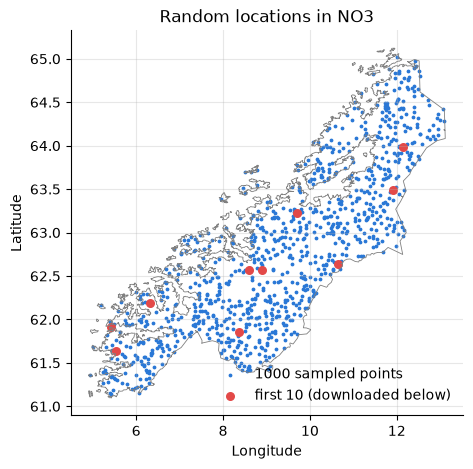

In [7]:
# The 1000 points of NO3 on top of the area outline
fig, ax = plt.subplots(figsize=(6, 5))
for part in getattr(AREAS["NO3"], "geoms", [AREAS["NO3"]]):
    ax.plot(*part.exterior.xy, color="grey", linewidth=0.6)
pts = locations[locations["area"] == "NO3"]
ax.scatter(pts["lon"], pts["lat"], s=3, color=PALETTE[0], label="1000 sampled points")
ax.scatter(pts["lon"][:10], pts["lat"][:10], s=30, color=PALETTE[7], label="first 10 (downloaded below)")
ax.set_title("Random locations in NO3")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(2)
ax.legend(loc="lower right", frameon=False)
plt.show()

## 4. open-meteo: ERA5 download function
open-meteo's documentation page (https://open-meteo.com/en/docs) builds the request
from a form and shows the matching Python code. The page has several sub-sections
that change *which kind* of data is served: the forecast API, the **Historical
Weather API** (`archive-api.open-meteo.com/v1/archive`), climate projections, and so
on. Inside the historical API, the *Reanalysis models* section chooses the model;
here it is `models=era5`. ERA5 is ECMWF's reanalysis on a 0.25 degree grid (~28 x
14 km in Norway), so open-meteo moves each point to the nearest grid cell.

**Why not all 1000 points?** The free API allows about 10,000 *weighted* calls per
day, and one location for a year of hourly data counts as roughly 26 calls (one per
two weeks). All 1000 points of one area would be ~26,000 calls, far more than a day's
quota. The function therefore downloads a random subset (the first `n_locations` of
the randomly ordered points, default 10) and the area is described by their average.
Requests are sent three at a time; more than that triggers open-meteo's rate limit
(HTTP 429), which is handled by waiting and retrying.

Variables: precipitation and temperature as required, plus rain, snowfall, wind speed,
relative humidity and cloud cover, which all matter for hydropower (snow fills the
reservoirs in spring; wind and clouds affect evaporation and the rest of the energy mix).

In [8]:
import time
from concurrent.futures import ThreadPoolExecutor

ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'

VARIABLES = ['temperature_2m', 'precipitation', 'rain', 'snowfall', 'wind_speed_10m', 'relative_humidity_2m', 'cloud_cover']


def _download_point(lon: float, lat: float, start: str, end: str, variables: list[str]) -> dict:
    """One open-meteo request for one location; retried on rate limits and server errors.

    open-meteo answers HTTP 429 when too many requests arrive at once, and now and then
    a 5xx. Waiting 2, 4, 8, ... seconds and trying again is the standard remedy.
    """
    params = {
        "latitude": round(lat, 4),
        "longitude": round(lon, 4),
        "start_date": start,
        "end_date": end,
        "hourly": ",".join(variables),
        "models": "era5",  # the reanalysis model asked for in the assignment
        "timezone": "UTC",
    }
    for attempt in range(6):
        response = requests.get(ARCHIVE_URL, params=params, timeout=300)
        if response.status_code == 200:
            return response.json()
        if response.status_code == 429 or response.status_code >= 500:
            time.sleep(2 ** (attempt + 1))
            continue
        response.raise_for_status()  # 4xx other than 429: a wrong request, no point retrying
    raise RuntimeError(f"open-meteo kept refusing the request (HTTP {response.status_code})")


def download_weather(
    area: str,
    start: str,
    end: str,
    locations: pd.DataFrame,
    n_locations: int = 10,
    variables: list[str] = VARIABLES,
    workers: int = 3,
) -> pd.DataFrame:
    """Hourly ERA5 weather for `n_locations` of the sampled points in one area.

    Parameters
    ----------
    area : area identifier, e.g. "NO3" (price area) or "Norway"
    start, end : first and last day, "YYYY-MM-DD" (both included)
    locations : the sampled points, columns area, order, lon, lat (from MongoDB)
    n_locations : how many of the 1000 sampled points to download. The points are
        stored in random order, so the first n are a random subset.
    variables : open-meteo hourly variable names
    workers : parallel requests; more than ~3 triggers open-meteo's rate limit

    Returns a long table: one row per location and hour, one column per variable.
    """
    points = (
        locations[locations["area"] == area].sort_values("order").head(n_locations)
    )
    if points.empty:
        raise ValueError(f"No sampled locations for area {area!r}")

    def fetch(row):
        answer = _download_point(row.lon, row.lat, start, end, variables)
        hourly = pd.DataFrame(answer["hourly"])
        hourly["time"] = pd.to_datetime(hourly["time"])
        hourly["location"] = row.order
        # open-meteo snaps each point to the nearest ERA5 grid cell (0.25 degrees)
        hourly["grid_lat"] = answer["latitude"]
        hourly["grid_lon"] = answer["longitude"]
        return hourly

    with ThreadPoolExecutor(max_workers=workers) as pool:
        frames = list(pool.map(fetch, points.itertuples()))
    return pd.concat(frames, ignore_index=True)


def area_average(weather: pd.DataFrame) -> pd.DataFrame:
    """Average over the downloaded locations: one row per hour, indexed by time."""
    columns = [c for c in weather.columns if c not in ("time", "location", "grid_lat", "grid_lon")]
    return weather.groupby("time")[columns].mean()

In [9]:
# Cache on disk, so re-running the notebook does not use the daily API quota again
CACHE = Path("../data/cache"); CACHE.mkdir(parents=True, exist_ok=True)   # git-ignored

def cached_weather(area, start, end, n_locations=10):
    path = CACHE / f"weather_{area}_{start}_{end}_{n_locations}.csv"
    if path.exists():
        return pd.read_csv(path, parse_dates=["time"])
    weather = download_weather(area, start, end, locations, n_locations)
    weather.to_csv(path, index=False)
    return weather

t0 = time.time()
weather = cached_weather("NO3", "2024-01-01", "2024-12-31")
print(f"{len(weather):,} rows in {time.time() - t0:.0f} s")
print("distinct ERA5 grid cells:", weather[["grid_lat", "grid_lon"]].drop_duplicates().shape[0], "of 10 points")
weather.head()

87,840 rows in 0 s
distinct ERA5 grid cells: 10 of 10 points


,time,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,relative_humidity_2m,cloud_cover,location,grid_lat,grid_lon
0,2024-01-01 00:00:00,-7.9,0.0,0.0,0.0,12.6,71,99,0,62.5,8.5
1,2024-01-01 01:00:00,-8.2,0.0,0.0,0.0,12.9,71,97,0,62.5,8.5
2,2024-01-01 02:00:00,-8.3,0.0,0.0,0.0,13.7,70,94,0,62.5,8.5
3,2024-01-01 03:00:00,-8.4,0.0,0.0,0.0,13.4,69,91,0,62.5,8.5
4,2024-01-01 04:00:00,-8.4,0.0,0.0,0.0,13.9,69,93,0,62.5,8.5


In [10]:
# Area average: one row per hour, mean over the 10 locations
no3 = area_average(weather)
no3.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
temperature_2m,8784.0,3.91,7.56,-16.93,-1.14,3.56,9.58,23.42
precipitation,8784.0,0.21,0.31,0.00,0.01,0.08,0.30,3.67
rain,8784.0,0.16,0.27,0.00,0.00,0.04,0.20,2.31
snowfall,8784.0,0.04,0.10,0.00,0.00,0.00,0.02,1.69
wind_speed_10m,8784.0,9.97,3.90,2.60,7.05,9.31,12.19,31.26
relative_humidity_2m,8784.0,79.83,11.34,31.50,73.50,82.30,88.50,97.60
cloud_cover,8784.0,79.40,22.43,0.00,69.20,87.20,97.50,100.00


## 5. Outliers in precipitation: DCT and Statistical Process Control
First the area-averaged hourly precipitation for NO3 in 2024.

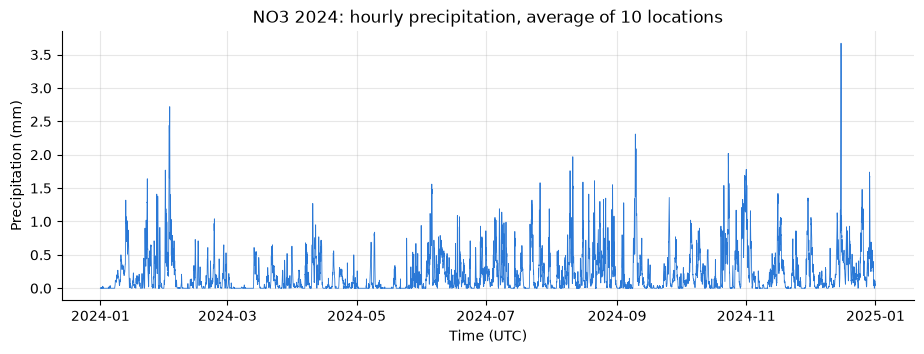

In [11]:
# Area-averaged hourly precipitation for the whole year (no filtering yet)
fig, ax = plt.subplots()
ax.plot(no3.index, no3["precipitation"], linewidth=0.6)
ax.set_title("NO3 2024: hourly precipitation, average of 10 locations")
ax.set_xlabel("Time (UTC)"); ax.set_ylabel("Precipitation (mm)")
plt.show()

**Method.** The precipitation is high-pass filtered with the Discrete Cosine Transform:
all DCT coefficients below a cut-off frequency are set to zero, and the inverse DCT
gives the *seasonally adjusted variations* (SATV). (The assignment calls them
*seasonally adjusted temperature variations*; here the same filter is applied to the
precipitation.) The part that was removed is the slow, seasonal level. Robust
statistics of the SATV for the whole year - the median and the MAD scaled by 1.4826
to estimate a standard deviation - give the width of the SPC band, and the
boundaries are the seasonal level +- `n_sd` robust standard deviations. So the
boundaries follow the season, and the SATV are only used to find them, not plotted.

Parameters: `cutoff` in cycles per year (default 12, i.e. variations slower than about
a month count as seasonal) and `n_sd` (default 3, the usual SPC choice).

In [12]:
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation

DATA_COLOUR, OUTLIER_COLOUR, BOUNDARY_COLOUR = ('#2a78d6', '#e34948', '#4a4a4a')


def _samples_per_year(index: pd.DatetimeIndex) -> float:
    """Sampling rate in samples per year, from the median time step."""
    step = pd.Series(index).diff().median()
    return pd.Timedelta(days=365.25) / step


def spc_outliers(series: pd.Series, cutoff: float = 12, n_sd: float = 3):
    """Statistical Process Control outliers, with boundaries from a DCT high-pass filter.

    1. DCT of the series; the coefficients for frequencies below `cutoff` (cycles per
       year) are set to zero, and the inverse DCT gives the high-pass filtered series,
       the seasonally adjusted variations (SATV). The removed part is the slow,
       seasonal level of the series.
    2. Robust statistics of the SATV for the whole period: the median as centre and
       the MAD (scaled by 1.4826, so it estimates a standard deviation) as spread.
    3. Boundaries = seasonal level + median +- n_sd * robust SD. They follow the
       season, so a value is an outlier compared with what is normal at that time.

    The SATV themselves are not plotted, only the data, boundaries and outliers.
    Returns (figure, summary dict).
    """
    x = series.to_numpy(dtype=float)
    n = len(x)
    # With an orthonormal DCT-II, coefficient k is the frequency k / (2n) cycles per
    # sample, so `cutoff` cycles per year corresponds to k = 2 * n * cutoff / rate
    k = int(round(2 * n * cutoff / _samples_per_year(series.index)))
    coefficients = dct(x, type=2, norm="ortho")
    coefficients[:k] = 0
    satv = idct(coefficients, type=2, norm="ortho")
    seasonal_level = x - satv

    centre = np.median(satv)
    robust_sd = 1.4826 * median_abs_deviation(satv)
    upper = seasonal_level + centre + n_sd * robust_sd
    lower = seasonal_level + centre - n_sd * robust_sd
    is_outlier = (x > upper) | (x < lower)

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(series.index, x, color=DATA_COLOUR, linewidth=0.7, label=series.name or "value")
    ax.plot(series.index, upper, color=BOUNDARY_COLOUR, linestyle="--", linewidth=0.8, label="SPC boundaries")
    ax.plot(series.index, lower, color=BOUNDARY_COLOUR, linestyle="--", linewidth=0.8)
    ax.scatter(series.index[is_outlier], x[is_outlier], color=OUTLIER_COLOUR, s=8, zorder=3, label="outliers")
    ax.set_title(f"SPC outliers (DCT cut-off {cutoff:g}/year, {n_sd:g} robust SD)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(series.name or "value")
    ax.legend(loc="upper left", frameon=False)
    fig.tight_layout()

    outliers = pd.DataFrame(
        {"value": x, "lower": lower, "upper": upper}, index=series.index
    )[is_outlier]
    summary = {
        "n_outliers": int(is_outlier.sum()),
        "share": float(is_outlier.mean()),
        "above_upper": int((x > upper).sum()),
        "below_lower": int((x < lower).sum()),
        "robust_sd": float(robust_sd),
        "dct_coefficients_removed": k,
        "outliers": outliers,
    }
    return fig, summary

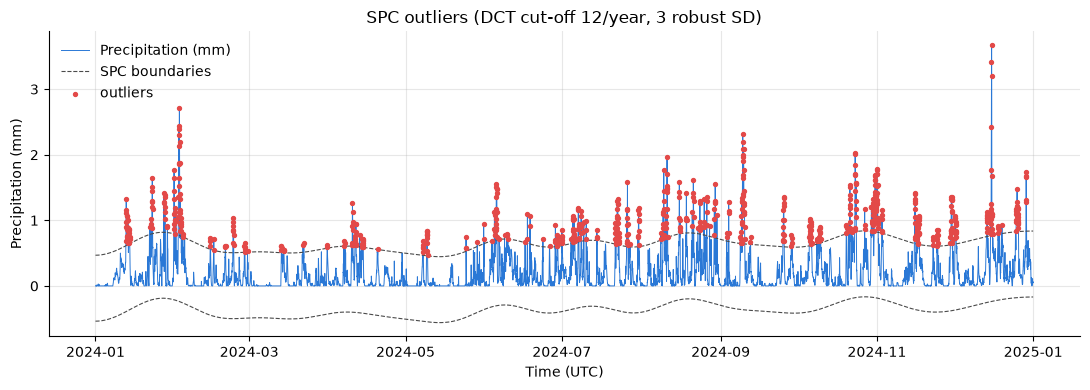

{'n_outliers': 705, 'share': 0.0803, 'above_upper': 705, 'below_lower': 0, 'robust_sd': 0.1676, 'dct_coefficients_removed': 24}


,value,lower,upper
time,,,
2024-12-15 18:00:00,3.67,-0.24,0.77
2024-12-15 17:00:00,3.42,-0.24,0.77
2024-12-15 19:00:00,3.20,-0.24,0.77
2024-02-02 18:00:00,2.72,-0.24,0.77
2024-02-02 12:00:00,2.44,-0.23,0.77
2024-12-15 16:00:00,2.43,-0.24,0.77
2024-02-02 17:00:00,2.39,-0.24,0.77
2024-09-09 15:00:00,2.31,-0.36,0.64
2024-02-02 13:00:00,2.30,-0.24,0.77


In [13]:
# Test 1: default parameters
fig, summary = spc_outliers(no3["precipitation"].rename("Precipitation (mm)"))
plt.show()
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items() if k != "outliers"})
summary["outliers"].sort_values("value", ascending=False).head(10).round(2)

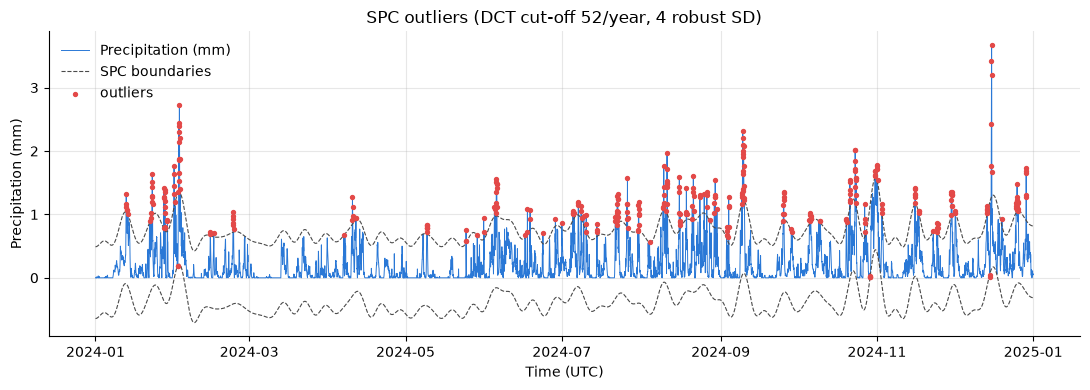

outliers: 341 (3.9%), DCT coefficients removed: 104


In [14]:
# Test 2: stricter band and a higher cut-off (weekly variations count as seasonal)
fig, summary2 = spc_outliers(no3["precipitation"].rename("Precipitation (mm)"), cutoff=52, n_sd=4)
plt.show()
print("outliers:", summary2["n_outliers"], f"({summary2['share']:.1%}),",
      "DCT coefficients removed:", summary2["dct_coefficients_removed"])

**Observations.**
- With the defaults (cut-off 12 cycles per year, 3 robust SD), 705 hours (8.0%) are
  outliers, and **all** of them are above the upper boundary. Precipitation cannot be
  negative and most hours are dry or almost dry, so the distribution is skewed to the
  right: the lower boundary is below zero and can never be crossed.
- 8% is far more than the 0.3% that 3 SD would give for normally distributed data. SPC
  with symmetric boundaries assumes roughly symmetric noise, which hourly rain is not.
  The outliers should be read as "heavy-rain hours", not as errors in the data.
- The outliers come in groups, one per weather event. The largest are 15 December 2024
  (3.7 mm per hour on average over the 10 locations), 2 February and 9 September.
- The boundaries follow the season: the upper boundary is higher in autumn and winter,
  the wettest part of the year in Mid-Norway.
- Test 2 (cut-off 52, 4 SD) is stricter and leaves 341 outliers (3.9%), mainly the cores
  of the same events.

## 6. Anomalies in temperature: Local Outlier Factor

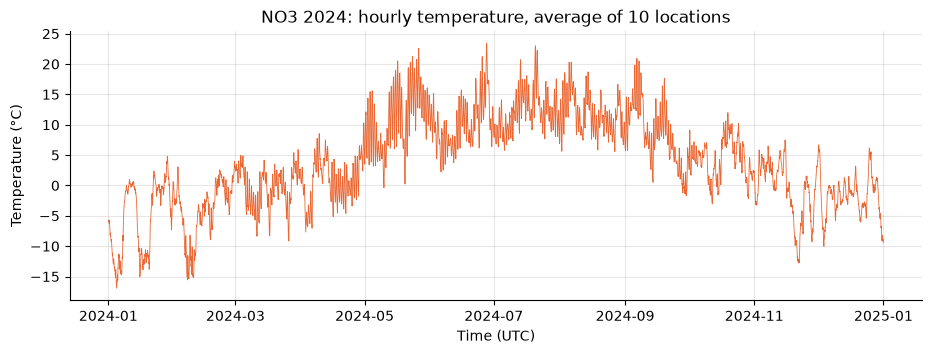

In [15]:
# Area-averaged hourly temperature for the whole year (no anomaly detection yet)
fig, ax = plt.subplots()
ax.plot(no3.index, no3["temperature_2m"], linewidth=0.6, color=PALETTE[1])
ax.set_title("NO3 2024: hourly temperature, average of 10 locations")
ax.set_xlabel("Time (UTC)"); ax.set_ylabel("Temperature (°C)")
plt.show()

**Method.** The Local Outlier Factor compares how densely packed the points are around
an observation with how densely packed they are around its nearest neighbours. Points
in a much thinner neighbourhood than their neighbours get a high factor. LOF is run on
two standardised features, time and temperature, so the neighbours of an hour are the
hours around it: an anomaly is a temperature that does not fit its local surroundings
(a sudden jump or cold spell), not just the coldest or warmest hours of the year.
`proportion` (default 1%) is the share of hours labelled as anomalies.

In [16]:
from sklearn.neighbors import LocalOutlierFactor


def lof_anomalies(series: pd.Series, proportion: float = 0.01, n_neighbors: int = 20):
    """Anomalies by the Local Outlier Factor (LOF) on (time, value).

    LOF compares the density around each point with the density around its nearest
    neighbours. Using time as a second feature makes the neighbours the hours
    nearby, so an anomaly is a value that does not fit its local surroundings (for
    example a sudden cold spell), not just the coldest hours of the year. Both features
    are standardised; time is scaled so that two months count as much as one standard
    deviation of the value.

    `proportion` is the share of points labelled as anomalies (scikit-learn's
    `contamination`). Returns (figure, summary dict).
    """
    values = series.to_numpy(dtype=float)
    days = (series.index - series.index[0]).total_seconds().to_numpy() / 86400
    features = np.column_stack([days / 60, (values - values.mean()) / values.std()])

    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=proportion)
    is_anomaly = lof.fit_predict(features) == -1
    scores = -lof.negative_outlier_factor_  # larger = more anomalous

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(series.index, values, color=DATA_COLOUR, linewidth=0.7, label=series.name or "value")
    ax.scatter(series.index[is_anomaly], values[is_anomaly], color=OUTLIER_COLOUR, s=10, zorder=3, label="LOF anomalies")
    ax.set_title(f"LOF anomalies ({proportion:.1%} of the hours, {n_neighbors} neighbours)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(series.name or "value")
    ax.legend(loc="upper left", frameon=False)
    fig.tight_layout()

    anomalies = pd.DataFrame({"value": values, "lof_score": scores}, index=series.index)[is_anomaly]
    summary = {
        "n_anomalies": int(is_anomaly.sum()),
        "share": float(is_anomaly.mean()),
        "mean_value_anomalies": float(values[is_anomaly].mean()),
        "mean_value_all": float(values.mean()),
        "anomalies": anomalies.sort_values("lof_score", ascending=False),
    }
    return fig, summary

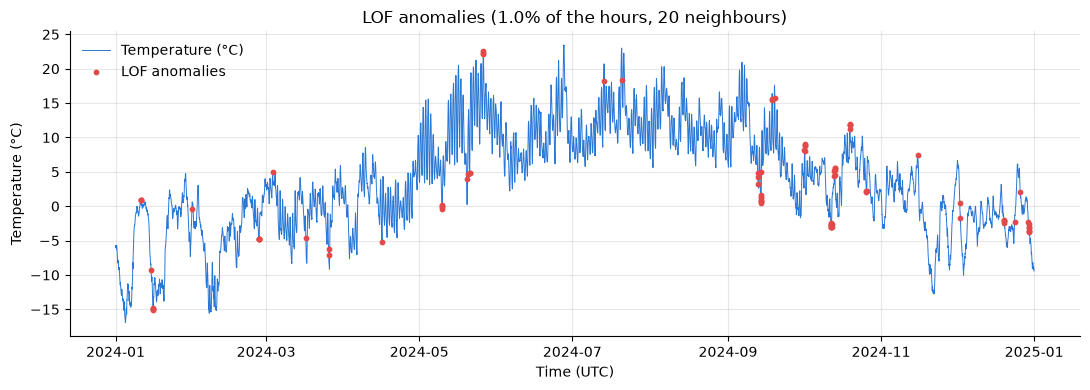

{'n_anomalies': 88, 'share': 0.01, 'mean_value_anomalies': 1.879, 'mean_value_all': 3.912}


,value,lof_score
time,,
2024-09-14 03:00:00,0.79,2.65
2024-12-29 19:00:00,-2.96,2.65
2024-09-14 02:00:00,0.83,2.64
2024-09-14 04:00:00,0.70,2.60
2024-12-29 18:00:00,-2.65,2.58
2024-12-29 17:00:00,-2.29,2.52
2024-05-20 06:00:00,4.63,2.51
2024-12-29 20:00:00,-3.18,2.49
2024-09-14 05:00:00,0.52,2.48


In [17]:
# Test 1: default, 1% of the hours
fig, summary = lof_anomalies(no3["temperature_2m"].rename("Temperature (°C)"))
plt.show()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in summary.items() if k != "anomalies"})
summary["anomalies"].head(10).round(2)

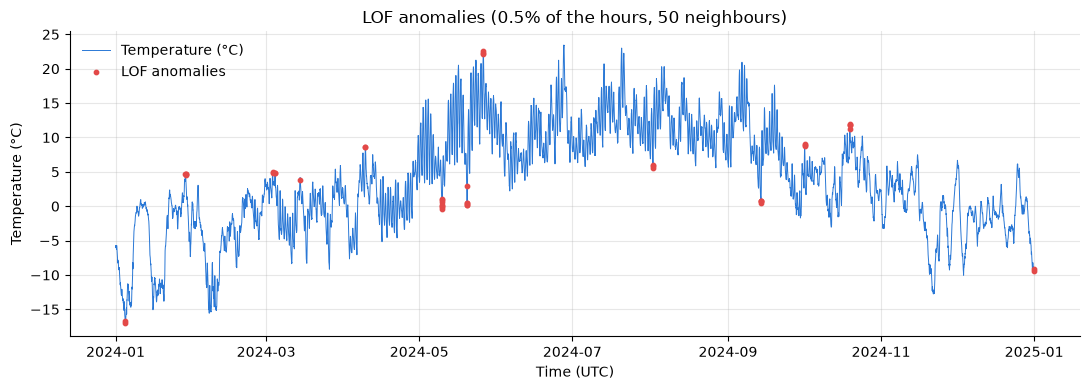

anomalies: 44


In [18]:
# Test 2: 0.5% anomalies and more neighbours (a wider "local" area)
fig, summary2 = lof_anomalies(no3["temperature_2m"].rename("Temperature (°C)"), proportion=0.005, n_neighbors=50)
plt.show()
print("anomalies:", summary2["n_anomalies"])

**Observations.**
- 88 hours (1%) are marked. They are not simply the coldest or warmest hours: their mean
  temperature is 1.9 °C, against 3.9 °C for the whole year, and many lie in the middle of
  the temperature range.
- They come in short groups where the temperature changes quickly compared with the
  hours around it. Examples are the night of 14 September (a sudden drop to about 0 °C),
  the evening of 29 December, and the start of the cold spell in mid-January (-15 °C).
- Test 2 (0.5%, 50 neighbours) halves the number to 44 and keeps the strongest of the
  same groups. More neighbours means "local" covers more hours, so short wiggles in the
  daily cycle count less.

## 7. STL decomposition of the reservoir fill level
The fill level comes straight from the Magasinstatistikk API, as in part 2. STL
(Seasonal-Trend decomposition using LOESS) splits the weekly series into a trend, a
seasonal pattern that may change slowly from year to year, and a residual:
observed = trend + seasonal + residual. The period is 52 weeks.

Parameters with defaults: `seasonal=13` (the seasonal pattern is smoothed over about
13 years, so it can change slowly), `trend=105` (about two years: long enough not to
follow the yearly cycle) and `robust=False`. With `robust=True`, unusual weeks get
less weight and end up in the residual instead of bending the trend and season.

In [19]:
BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
nve = pd.DataFrame(requests.get(f"{BASE}/HentOffentligData", timeout=60).json())
nve["dato_Id"] = pd.to_datetime(nve["dato_Id"])
# Weekly fill level of price area NO3, sorted (the API returns the rows shuffled)
fill_no3 = (nve[(nve["omrType"] == "EL") & (nve["omrnr"] == 3)]
            .sort_values("dato_Id").set_index("dato_Id")["fyllingsgrad"]
            .rename("fill level NO3"))
print(len(fill_no3), "weeks,", fill_no3.index.min().date(), "-", fill_no3.index.max().date())

1661 weeks, 1995-01-08 - 2026-11-01


In [20]:
from statsmodels.tsa.seasonal import STL


def stl_decomposition(
    series: pd.Series,
    period: int = 52,
    seasonal: int = 13,
    trend: int = 105,
    robust: bool = False,
):
    """Seasonal-Trend decomposition using LOESS (STL), plotted as four panels.

    `period` is the season length in samples (52 weeks for weekly data). `seasonal`
    and `trend` are the lengths of the LOESS smoothers: larger values give a seasonal
    pattern that changes more slowly between years and a smoother trend. statsmodels
    needs both to be odd (and trend > period), so even values are rounded up.
    `robust` down-weights unusual weeks so they end up in the residual.
    Returns the figure.
    """
    seasonal = seasonal + 1 - seasonal % 2  # nearest odd number at or above
    trend = max(trend, period + 1)
    trend = trend + 1 - trend % 2
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    parts = {
        "Observed": result.observed,
        "Trend": result.trend,
        "Seasonal": result.seasonal,
        "Residual": result.resid,
    }
    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    for ax, (name, values) in zip(axes, parts.items()):
        if name == "Residual":
            ax.scatter(series.index, values, s=3, color=DATA_COLOUR)
            ax.axhline(0, color=BOUNDARY_COLOUR, linewidth=0.8)
        else:
            ax.plot(series.index, values, color=DATA_COLOUR, linewidth=1)
        ax.set_ylabel(name)
    axes[0].set_title(
        f"STL of {series.name or 'series'} (period {period}, seasonal {seasonal}, "
        f"trend {trend}, robust={robust})"
    )
    axes[-1].set_xlabel("Date")
    fig.tight_layout()
    return fig

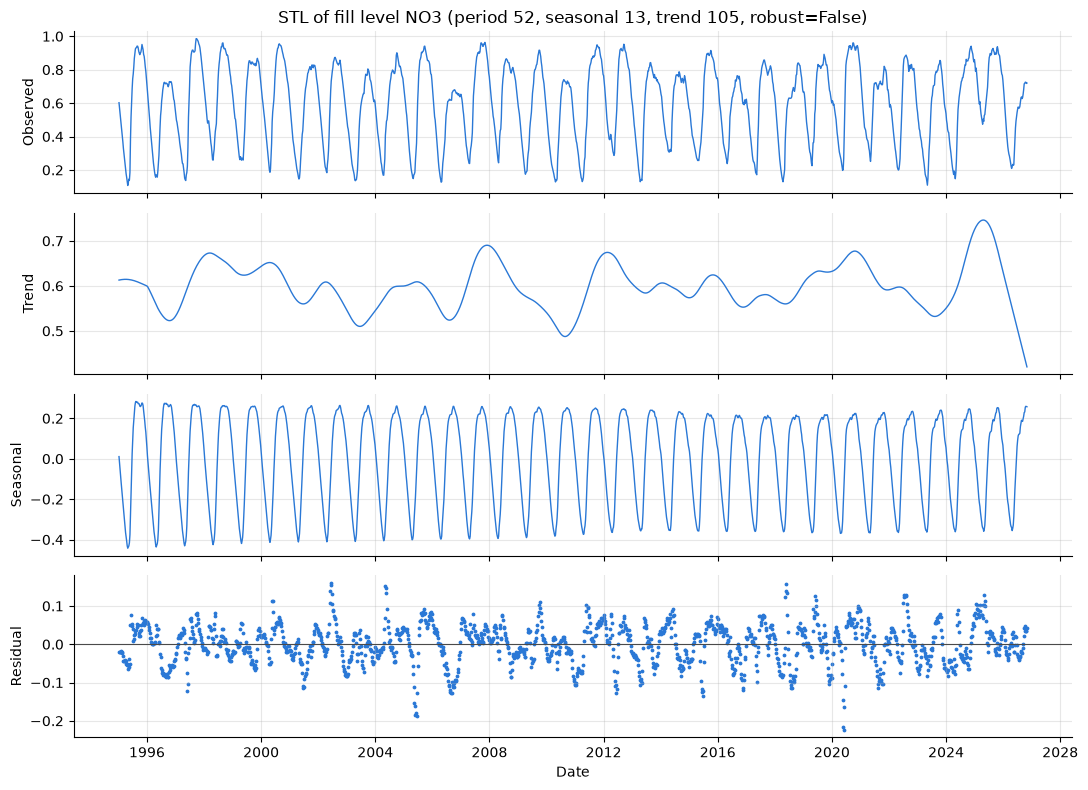

In [21]:
# Test 1: default parameters
fig = stl_decomposition(fill_no3)
plt.show()

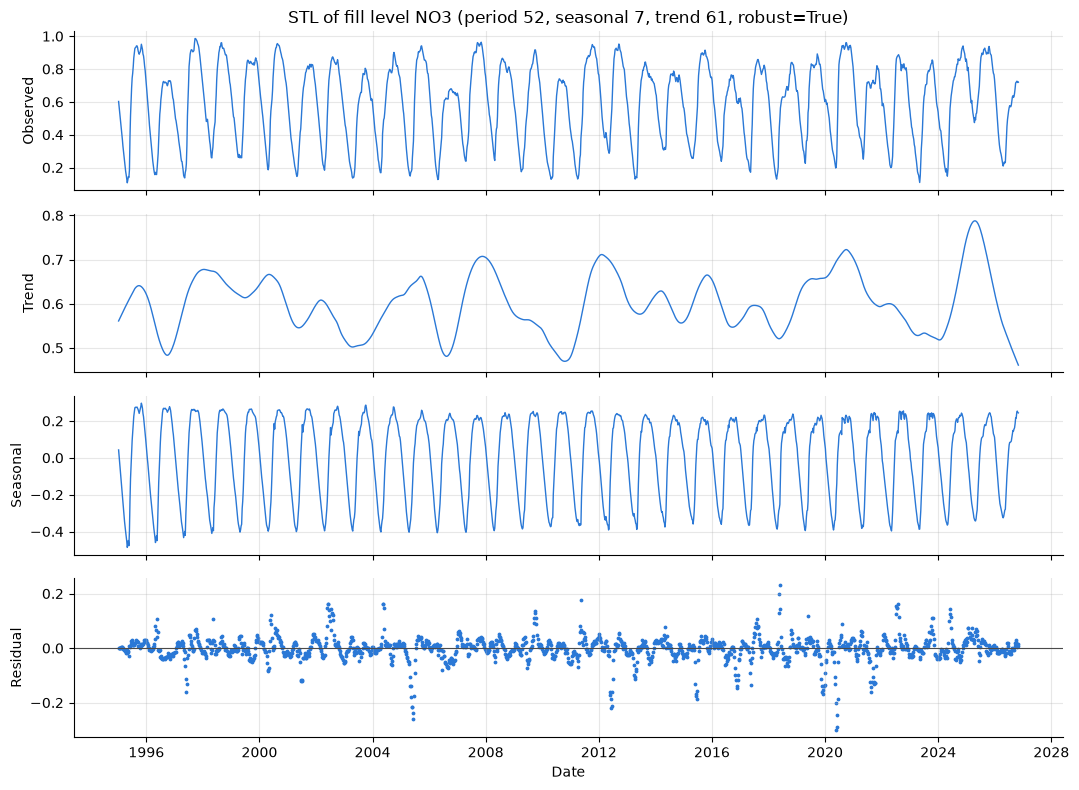

In [22]:
# Test 2: robust fit, shorter smoothers (even numbers are rounded up to odd)
fig = stl_decomposition(fill_no3, seasonal=7, trend=60, robust=True)
plt.show()

**Observations.**
- The seasonal component is the largest part of the series. The reservoirs are lowest
  in April-May, just before the snow melts (about 0.4 below the trend), and fullest in
  autumn (about 0.25 above the trend). Its shape changes only slowly over 30 years.
- The trend moves between about 0.5 and 0.7 and shows wet and dry years. For example,
  it is low in 1996, 2003 and 2010-2011 (dry years with low reservoirs in Norway) and high in
  2008, 2012 and 2020.
- The sharp fall at the very end of the trend is an **edge effect**. The data stop in the
  autumn of the current year, so LOESS has only one side to smooth over there. The last
  year of the trend should not be interpreted.
- With `robust=True` and shorter smoothers (test 2), most residuals are close to zero and
  a few weeks stand out clearly (e.g. 2005, 2012, 2020). Robust STL puts unusual weeks
  in the residual instead of letting them bend the trend and the season.

## 8. Spectrogram of the reservoir fill level
The short-time Fourier transform cuts the series into overlapping windows and gives
the frequency content of each window; plotted over time this is a spectrogram. With
weekly data, a window of 156 samples is three years, so frequencies are resolved in
steps of 1/3 cycle per year, and with an overlap of 130 the windows move half a year
at a time. The frequency axis is in cycles per year.

In [23]:
from scipy.signal import stft


def spectrogram(series: pd.Series, window: int = 156, overlap: int = 130, max_frequency: float = 6):
    """Spectrogram from a short-time Fourier transform (scipy.signal.stft).

    The series is cut into overlapping windows of `window` samples, each moved
    `window - overlap` samples on, and the Fourier transform of each window gives one
    column of the image. The frequency axis is in cycles per year, so a yearly cycle
    shows up as a bright band at 1. A long window gives sharp frequencies but blurry
    timing, and the other way round. The mean is subtracted first, so the constant
    level (frequency 0) does not dominate the colour scale.
    Returns the figure.
    """
    overlap = min(overlap, window - 1)  # stft needs overlap < window
    rate = _samples_per_year(series.index)  # samples per year
    values = series.to_numpy(dtype=float)
    freqs, times, z = stft(values - values.mean(), fs=rate, nperseg=window, noverlap=overlap)

    # stft gives times in years from the start; convert to dates for the x-axis
    dates = series.index[0] + pd.to_timedelta(times * 365.25, unit="D")
    fig, ax = plt.subplots(figsize=(11, 4))
    mesh = ax.pcolormesh(dates, freqs, np.abs(z), shading="gouraud", cmap="viridis")
    ax.set_ylim(0, min(max_frequency, freqs.max()))
    ax.set_title(f"Spectrogram of {series.name or 'series'} (window {window}, overlap {overlap} samples)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Frequency (cycles per year)")
    fig.colorbar(mesh, ax=ax, label="Amplitude")
    fig.tight_layout()
    return fig

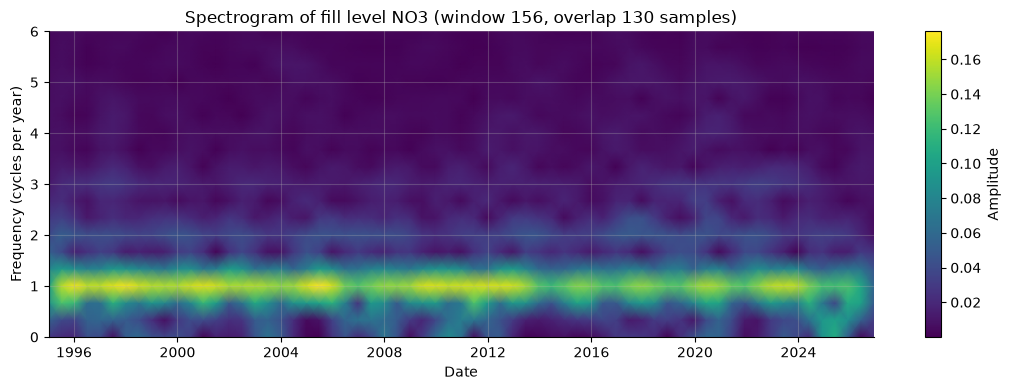

In [24]:
# Test 1: default window (3 years) and overlap
fig = spectrogram(fill_no3)
plt.show()

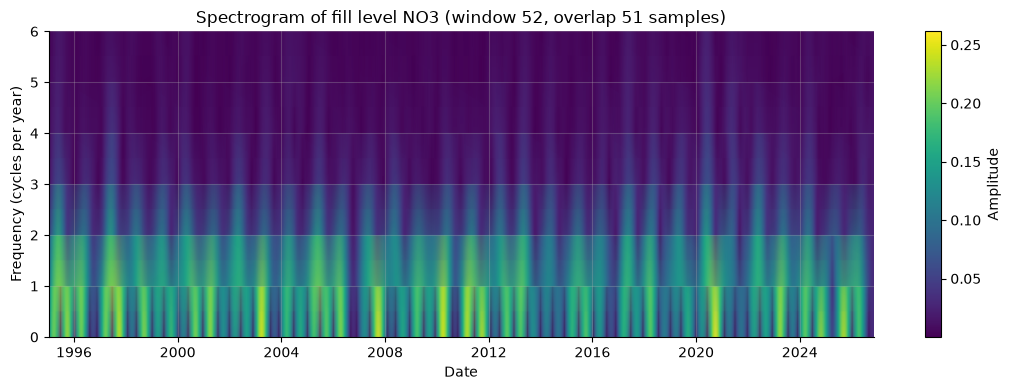

In [25]:
# Test 2: a one-year window gives sharper timing but blurrier frequencies;
# an overlap larger than the window is reduced to window - 1
fig = spectrogram(fill_no3, window=52, overlap=60)
plt.show()

**Observations.**
- The bright band at **1 cycle per year** is the yearly filling and emptying cycle, and it
  is present in every window from 1995 to today. A weaker band at 2 cycles per year is a
  harmonic: the cycle is not a pure sine (it falls slowly through winter and rises fast
  in May-June).
- The strength of the yearly band varies between windows, e.g. weaker around 2007 and
  2015. These are periods where the trend and the residual took more of the variation.
- Test 2 (a one-year window) shows the trade-off: the timing is sharper, but the
  frequency resolution is 1 cycle per year, so energy is smeared across whole bands. The
  overlap of 60 was larger than the window and was reduced to 51, as the function
  promises.

## 9. AI usage
I used Claude Code (Anthropic) as a pair programmer in VS Code, as in parts 1 and 2:
- **Areas:** finding the map services behind atlas.nve.no (price areas, NVE regions and the
  REGINE catchments), and the idea of clipping the areas to land after a test showed that
  many random points were in the sea.
- **Notebook:** code for the sampling, the open-meteo download (parallel requests, retries
  on rate limits, disk cache) and the four analysis functions (DCT/SPC, LOF, STL and
  spectrogram), as well as explaining the methods in the text cells.
- **Streamlit:** the global area selector in the sidebar, the two new pages with tabs, the
  new page order, and the fixes from the part 2 peer review. The pages were tested with
  Streamlit's `AppTest` before deploying.
- **Log and observations:** the AI wrote first drafts from the results, and I edited them.

I ran the notebook and the app myself, compared the plots with the numbers, and checked
the deployed app.

## 10. Log
In this part I added weather data and time-series analysis to the project.

The first task was the areas. The price areas were easy to find on atlas.nve.no, and
instead of downloading files by hand I query the map service behind the portal, which
returns the same polygons as GeoJSON. The precipitation areas took longer. The
Magasinstatistikk API has three watercourse areas, and on the map they match NVE's five
regions. East is RS+RØ, West is RV and North is RM+RN, so I merge the regions.

When I sampled 1000 random points per area, I found that the NVE polygons include the
coastal sea. Up to 40% of the points in NO4 were in the sea. Checking every point with an
elevation API would use up the daily quota, so I clip each area to the union of NVE's
catchments instead. Catchments are land by definition. I also draw latitude uniformly in
sin(latitude), so every square kilometre has the same chance.

The open-meteo download was mostly about limits. A year of hourly data for one location
counts as about 26 calls, and the free quota is about 10,000 per day, so I cannot download
all 1000 points of an area. The function downloads a random subset (10 by default) and
averages them. Single-point requests in three parallel threads were much faster than one
request with many points. A 429 answer means wait and try again.

The analyses were each written as a function that returns a figure and a summary. The
interesting result was in the SPC: all precipitation outliers were above the upper
boundary, because rain is skewed and never negative. LOF found sudden temperature changes
rather than the coldest hours. STL and the spectrogram both show how strong the yearly
reservoir cycle is, and STL also showed me its edge effect at the end of the series.

In Streamlit I moved the area selector to the sidebar, so it is shared by all pages and
the weather always matches the reservoir area. The download is an automatic, cached part
of the weather page, with the settings in an expander, because a separate download page
would only add a click. The two new pages use tabs, and the pages are grouped in the menu
by data source. I also fixed the points from the part 2 peer review: the cross-border flows
can be shown as one small panel per connection, and the misleading first-week dip in the
weekly change is removed.

Everything was developed on the branch part3 and merged into main after the feedback, so
the app address is the same.